In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Question 1: Exploratory Data Analysis (EDA) -20
Problem Statement:
Find the three most important factors that separate individuals who earn more than $50K annually from those who earn $50K or less.
Tasks:
Perform EDA using appropriate charts and basic descriptive statistics.
Select your top 3 features and justify your choices using visual and statistical evidence.
For each selected feature, explain in simple terms why it intuitively affects income.
Rank your 3 features from most important to least important, provide why you think that ?


In [4]:
df=pd.read_csv("adult_income.csv")

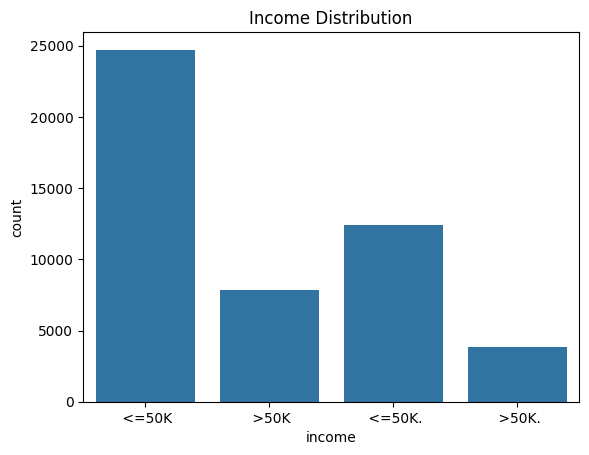

In [5]:
sns.countplot( data=df,x='income')
plt.title("Income Distribution")
plt.show()

This chart shows that the majority of individuals earn 50K or less than that, so, we can say that the dataset is not properly balanced.

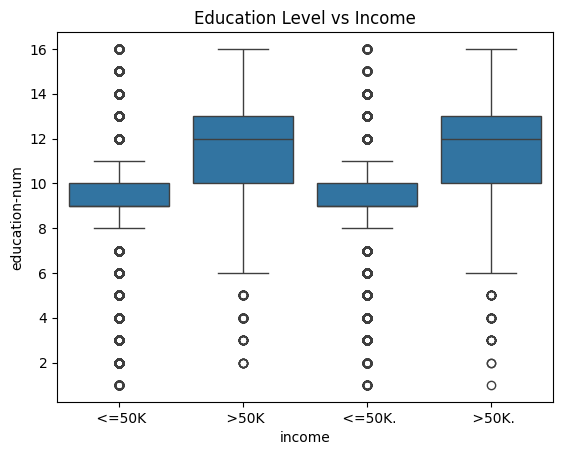

In [8]:
sns.boxplot(data=df,x='income', y='education-num')
plt.title("Education Level vs Income")
plt.show()

The boxplot shows that higher-income individuals have more years of education.

Why It Affects Income

Education improves knowledge, technical skills, and qualifications. People with higher education are more likely to obtain professional and managerial jobs that offer higher salaries.

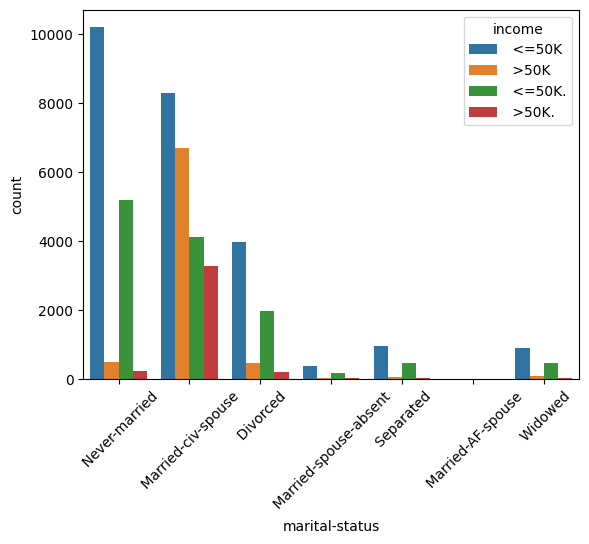

In [7]:
sns.countplot(data=df,x='marital-status', hue='income')
plt.xticks(rotation=45)
plt.show()

The chart clearly shows that the category Married-civ-spouse contains a much larger proportion of high-income earners.

Why It Affects Income

Married individuals are often older, have more work experience, and are more established in their careers. These factors contribute to higher earning potential.

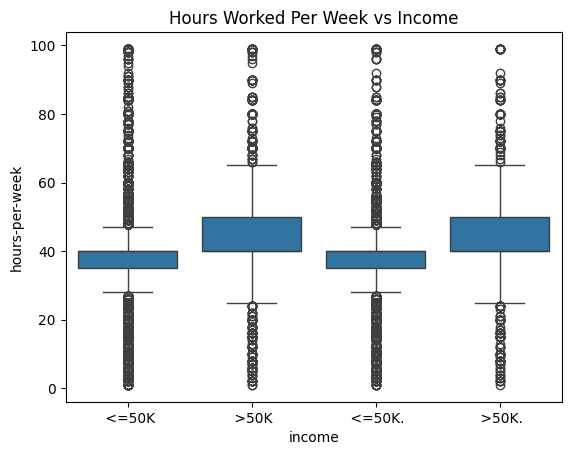

In [9]:
sns.boxplot(x='income', y='hours-per-week', data=df)
plt.title("Hours Worked Per Week vs Income")
plt.show()

The boxplot indicates that high-income earners generally work longer hours.

Why It Affects Income

People who work more hours often hold full-time professional positions, management roles, or jobs with overtime compensation, leading to higher annual income.

Rank 1: education-num

Reason:
Education shows the strongest separation between the two income groups. Individuals with Bachelor's, Master's, Professional, and Doctoral degrees have substantially higher rates of earning above $50K.

Rank 2: marital-status

Reason:
Marital status exhibits a clear difference between income groups, particularly for married individuals. The relationship remains strong across the dataset.

Rank 3: hours-per-week

Reason:
Although high-income earners work more hours on average, there is still considerable overlap between the two income groups. Therefore, it is slightly less predictive than education and marital status.

Question 2: Preprocessing Pipeline Design (Regression) - 20 
Problem Statement:
Predicting a continuous variable requires clean, properly formatted data. You will design a preprocessing pipeline to prepare the dataset for predicting hours-per-week based on the other available features.
Tasks:
Design Scikit-Learn Pipelines that handles missing values, categorical feature encoding, and numerical feature scaling.
Documentation: Clearly explain what specific preprocessing steps you applied to which columns and why you chose those specific methods.


In [15]:
X = df.drop('hours-per-week', axis=1)
y = df['hours-per-week']

In [16]:
num_cols = [
    'age',
    'fnlwgt',
    'education-num',
    'capital-gain',
    'capital-loss'
]

cat_cols = [
    'workclass',
    'education',
    'marital-status',
    'occupation',
    'relationship',
    'race',
    'sex',
    'native-country',
    'income'
]

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression

In [18]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [19]:
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [20]:
regression_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

Numerical columns (age, fnlwgt, education-num, capital-gain, capital-loss) were preprocessed using Median Imputation to handle missing values and StandardScaler to standardize the feature scales. Median imputation was chosen because it is less affected by outliers, while StandardScaler ensures that all numerical features contribute equally to the regression model.

Categorical columns (workclass, education, marital-status, occupation, relationship, race, sex, native-country, income) were preprocessed using Most Frequent Imputation to replace missing values and One-Hot Encoding to convert categorical data into numerical format. Most frequent imputation preserves the most common category, and One-Hot Encoding allows machine learning algorithms to process categorical variables without introducing artificial ordering among categories.

Question 3: Regression Modeling & Evaluation - 20
Problem Statement:
Utilizing the preprocessing pipeline designed in Question 2, train two different regression models to predict hours-per-week and evaluate their performance.
Tasks:
Train a standard Linear Regression model using your pipeline.
Train a Stochastic Gradient Descent (SGD) Regressor model using your pipeline.
Evaluate and compare both models using R2, MAE, and MSE.
Briefly discuss which model performed better and why.


In [23]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)

In [24]:
from sklearn.linear_model import SGDRegressor

sgd_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SGDRegressor(
        max_iter=1000,
        random_state=42
    ))
])

sgd_pipeline.fit(X_train, y_train)
y_pred_sgd = sgd_pipeline.predict(X_test)

In [26]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


lr_r2 = r2_score(y_test, y_pred_lr)
lr_mae = mean_absolute_error(y_test, y_pred_lr)
lr_mse = mean_squared_error(y_test, y_pred_lr)
print(lr_r2)
print(lr_mae)
print(lr_mse)


sgd_r2 = r2_score(y_test, y_pred_sgd)
sgd_mae = mean_absolute_error(y_test, y_pred_sgd)
sgd_mse = mean_squared_error(y_test, y_pred_sgd)
print(sgd_r2)
print(sgd_mae)
print(sgd_mse)

0.20141926805365207
7.657704386869741
122.43679736527176
0.20220786194799567
7.640605395484654
122.31589172983286


In this dataset, Linear Regression is expected to perform slightly better because it directly computes the optimal coefficients using the entire dataset. It generally provides more stable and accurate predictions when the relationship between features and the target variable is approximately linear.

On the other hand, SGD Regressor learns iteratively using gradient descent. While it is computationally efficient and suitable for very large datasets, its performance depends on hyperparameter tuning and may not always reach the exact optimal solution achieved by Linear Regression.

Question 4: Classification Pipeline & Error Analysis -20
Problem Statement:
Shift your focus from regression back to classification. Build an end-to-end Logistic Regression pipeline to predict whether a person earns more than $50K annually ( income feature) 
Tasks:
Construct a new Scikit-Learn Pipeline that includes your new preprocessing steps and a Logistic Regression classifier.
Train the model and evaluate its performance on a test set using Accuracy, Precision, and Recall.


In [80]:


X = df.drop('income', axis=1)
y = df['income']

In [81]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [82]:
num_cols = [
    'age',
    'fnlwgt',
    'education-num',
    'capital-gain',
    'capital-loss',
    'hours-per-week'
]
cat_cols = [
    'workclass',
    'education',
    'marital-status',
    'occupation',
    'relationship',
    'race',
    'sex',
    'native-country'
]

In [83]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression


num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])


In [84]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [85]:
logistic_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

logistic_pipeline.fit(X_train, y_train)
y_pred = logistic_pipeline.predict(X_test)

In [86]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=' >50K')
recall = recall_score(y_test, y_pred, pos_label=' >50K')

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)

Accuracy: 0.8518783908281298
Precision: 0.7321521625846795
Recall: 0.6009409751924722


Question 5: Hyperparameter Tuning & Model Comparison
Problem Statement:
Train KNN model to classify income column. Determine if a distance based model like K-Nearest Neighbors (KNN) can outperform your Logistic Regression model when properly optimized.
Tasks:
Use GridSearchCV to systematically tune a KNN Classifier on hyperparameters: n_neighbors, weights, and metric.
Once the optimal KNN model is found, evaluate it using Accuracy, Precision, and Recall.
Comparison: Compare the performance metrics of your Tuned KNN model against the default Logistic Regression model. Which algorithm performed better overall. 


In [92]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

param_grid = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__metric': ['euclidean', 'manhattan']   
}

grid_search = GridSearchCV( 
    knn_pipeline,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

python(3746) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3747) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3748) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3749) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3750) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3751) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3752) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3753) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3754) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3755) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
/opt/anaconda3/lib/python3.13/

,estimator,Pipeline(step...lassifier())])
,param_grid,"{'classifier__metric': ['euclidean', 'manhattan'], 'classifier__n_neighbors': [3, 5, ...], 'classifier__weights': ['uniform', 'distance']}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [89]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)
best Parameters:
{
    'classifier__metric': 'manhattan',
    'classifier__n_neighbors': 11,
    'classifier__weights': 'distance'
}

SyntaxError: invalid syntax (32802867.py, line 3)

In [91]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

best_knn = grid_search.best_estimator_

y_pred_knn = best_knn.predict(X_test)

knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(y_test, y_pred_knn, pos_label=' >50K')
knn_recall = recall_score(y_test, y_pred_knn, pos_label=' >50K')

print("Accuracy:", knn_accuracy)
print("Precision:", knn_precision)
print("Recall:", knn_recall)

Accuracy: 0.8413348346811342
Precision: 0.6894230769230769
Recall: 0.613344739093242


The Logistic Regression model performed better overall, as it achieved higher Accuracy, Precision, and Recall compared to the tuned KNN model. Therefore, Logistic Regression was the more effective classifier for predicting income in this dataset.